# 04 · Explore the SpatialFusion datasets (`SpatialData`)

Loads one or more of the built Xenium datasets (`OVCA`, `PRAD`, `BRCA`) as
[`SpatialData`](https://spatialdata.scverse.org/) objects and explores each end-to-end:
spatial annotation maps via **`spatialdata-plot`** and a transcriptomic **UMAP** via the
standard `scanpy` pipeline (normalize → log1p → PCA → neighbors → Leiden → UMAP) run on the
per-cell gene-expression matrix in `tables['table']`.

**To use:** edit `DATASETS` in the config cell to pick which datasets to load, then run all.
Plots use a low `DPI` so the saved `.ipynb` stays small and opens quickly.

Each `.zarr` (built by `scripts/preprocess/build_<name>.py`) bundles `images` (`he` + `morphology_focus`),
`labels`/`shapes` (native `cell_labels`/`nucleus_labels` + `*_boundaries`), and
`tables['table']` (cell × gene matrix with `obs['cell_type']`, `domain`).

> Run with the **`wsi`** Jupyter kernel (`envs/wsi.yml`). See `notebooks/datasets/DATASETS.md`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import scanpy as sc
import spatialdata as sd
import spatialdata_plot  # noqa: F401  (registers the `.pl` accessor)

# ---- choose what to explore ----
DATASETS  = ["OVCA"]      # any subset of: "OVCA", "PRAD", "BRCA"
DPI       = 50            # low dpi -> small inline images so the .ipynb opens fast
SUBSAMPLE = 50_000        # cells used for the scanpy/UMAP pipeline (None = all)

mpl.rcParams["figure.dpi"]  = DPI
mpl.rcParams["savefig.dpi"] = DPI
sc.settings.set_figure_params(dpi=DPI, frameon=False)
DATA_DIR = Path("datasets")

## Helpers

One function per step so the loop below reads top-to-bottom. The table annotates the
`cell_labels` raster (`spatialdata_attrs.region`), so spatial maps colour the **labels**
element (not the `*_boundaries` shapes, which the table does not annotate).

In [2]:
def load(name):
    z = DATA_DIR / f"{name}.zarr"
    assert z.exists(), f"{z} not found — build it with scripts/preprocess/build_{name.lower()}.py"
    sdata = sd.read_zarr(z)
    table = sdata.tables[list(sdata.tables)[0]]
    attrs = table.uns.get("spatialdata_attrs", {})
    cell_labels = attrs.get("region") if attrs.get("region") in sdata.labels else next(
        (l for l in sdata.labels if "cell" in l and "nucle" not in l), list(sdata.labels)[0])
    return sdata, table, cell_labels


def overview(name, sdata, table, cell_labels):
    print(f"=== {name} ===")
    print("images:", list(sdata.images), "| labels:", list(sdata.labels),
          "| shapes:", list(sdata.shapes), "| points:", list(sdata.points))
    print("table :", table.shape, "| colouring labels element:", cell_labels)
    for c in ("cell_type", "domain"):
        if c in table.obs:
            print(f"\n{c}:\n{table.obs[c].value_counts(dropna=False)}")


def plot_spatial(name, sdata, table, cell_labels):
    if "he" in sdata.images:
        fig, ax = plt.subplots(figsize=(5, 5))
        sdata.pl.render_images("he").pl.show(ax=ax)
        ax.set_title(f"{name} — H&E"); plt.show()
    cols = [c for c in ("cell_type", "domain") if c in table.obs]
    fig, axes = plt.subplots(1, len(cols), figsize=(5 * len(cols), 4.5), squeeze=False)
    for ax, c in zip(axes[0], cols):
        sdata.pl.render_labels(cell_labels, color=c).pl.show(ax=ax)
        ax.set_title(f"{name} — {c}")
    plt.tight_layout(); plt.show()


def plot_composition(name, table):
    if not {"domain", "cell_type"} <= set(table.obs):
        return
    comp = pd.crosstab(table.obs["domain"], table.obs["cell_type"], normalize="index")
    ax = comp.plot(kind="barh", stacked=True, figsize=(8, 4), colormap="tab20", width=0.85)
    ax.set_xlabel("fraction of cells"); ax.set_ylabel("domain")
    ax.set_title(f"{name} — cell-type composition per domain")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=7, title="cell_type")
    plt.tight_layout(); plt.show()


def run_scanpy(name, table):
    """Standard scanpy pipeline on the per-cell transcriptome (subsampled)."""
    ad = table.copy()
    if SUBSAMPLE and ad.n_obs > SUBSAMPLE:
        sc.pp.subsample(ad, n_obs=SUBSAMPLE, random_state=0)
    ad.layers["counts"] = ad.X.copy()
    sc.pp.normalize_total(ad, target_sum=1e4)
    sc.pp.log1p(ad)
    sc.pp.pca(ad, n_comps=50)
    sc.pp.neighbors(ad, n_neighbors=15)
    sc.tl.umap(ad)
    sc.tl.leiden(ad, resolution=1.0, flavor="igraph", n_iterations=2, directed=False)
    cols = [c for c in ("cell_type", "domain", "leiden") if c in ad.obs]
    print(f"{name}: scanpy on {ad.n_obs:,} cells x {ad.n_vars:,} genes → "
          f"{ad.obs['leiden'].nunique()} Leiden clusters")
    sc.pl.umap(ad, color=cols, ncols=len(cols), wspace=0.4, title=[f"{name} — {c}" for c in cols])
    return ad

## Explore the selected datasets

For each dataset: print contents + annotation counts, draw the H&E and spatial
cell-type/domain maps, the composition bar, and the transcriptomic UMAP. Processed
`AnnData` objects are kept in `results[name]` for further poking.

=== OVCA ===
images: ['he', 'morphology_focus'] | labels: ['cell_labels', 'nucleus_labels'] | shapes: ['cell_boundaries', 'nucleus_boundaries'] | points: ['domain_points']
table : (407124, 5101) | colouring labels element: cell_labels

cell_type:
cell_type
Malignant      207860
Stromal        125481
Myeloid         27415
Endothelial     22062
Lymphoid         9999
Epithelial       6982
Pericytes        4828
Unassigned       1984
NaN               513
Name: count, dtype: int64

domain:
domain
Tumor             212828
Unassigned         92151
NaN                68429
Smooth muscle      17057
Necrosis            8122
Fallopian tube      6844
Ovary               1693
Name: count, dtype: int64


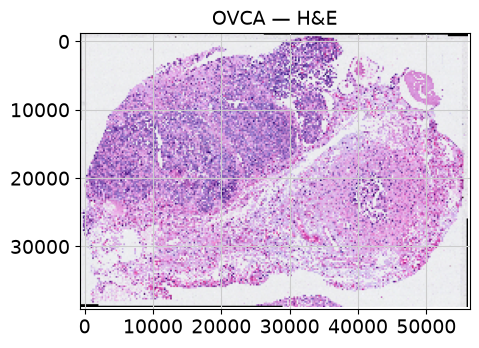

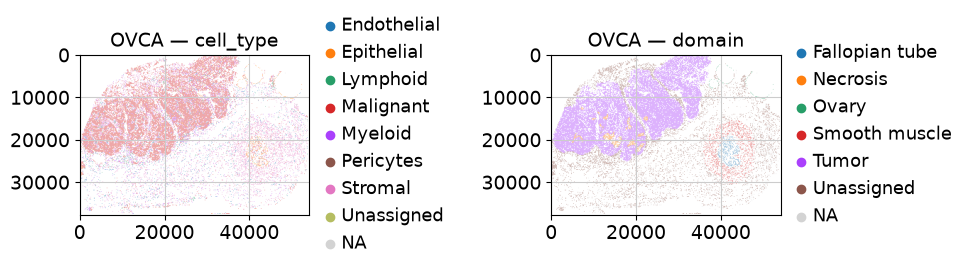

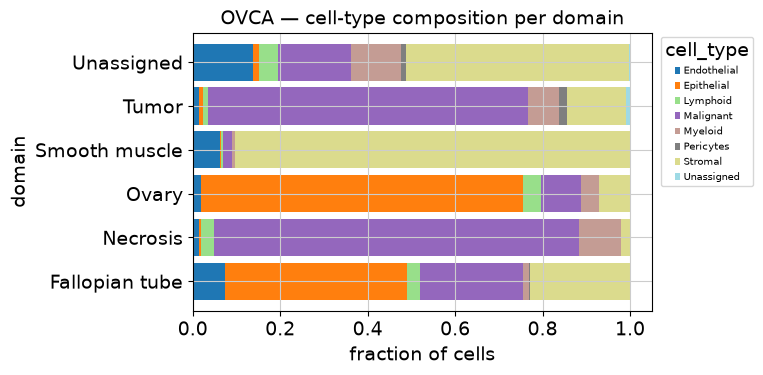

In [ ]:
results = {}
for name in DATASETS:
    sdata, table, cell_labels = load(name)
    overview(name, sdata, table, cell_labels)
    plot_spatial(name, sdata, table, cell_labels)
    plot_composition(name, table)
    results[name] = run_scanpy(name, table)

In [ ]:
sdata

SpatialData object, with associated Zarr store: /data/ddimitrov/repos/wsi_cellina/notebooks/datasets/BRCA.zarr
├── Images
│     ├── 'he': DataArray[cyx] (3, 24241, 30786)
│     ├── 'morphology_focus': DataTree[cyx] (1, 25778, 35416), (1, 12889, 17708), (1, 6444, 8854), (1, 3222, 4427), (1, 1611, 2213)
│     └── 'morphology_mip': DataTree[cyx] (1, 25778, 35416), (1, 12889, 17708), (1, 6444, 8854), (1, 3222, 4427), (1, 1611, 2213)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (25778, 35416), (12889, 17708), (6444, 8854), (3222, 4427), (1611, 2213)
│     └── 'nucleus_labels': DataTree[yx] (25778, 35416), (12889, 17708), (6444, 8854), (3222, 4427), (1611, 2213)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (167780, 1) (2D shapes)
│     ├── 'nucleus_boundaries': GeoDataFrame shape: (167780, 1) (2D shapes)
│     └── 'pathology_regions': GeoDataFrame shape: (4, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (167780, 313)
with coordinate systems:
    ▸ 'global', with ele